# Solar farm output: a range for every half hour is not a range for the day

**Two forecasts of a solar farm's next day give the same range for every half hour, and score the same to the last digit. Asked for the day's total energy, one gives a range that holds on 84% of days and the other on 33%. The difference is whether a forecast keeps a whole day together, and only a score that looks at the whole day at once can see it. TimeGym takes forecasts made of whole possible days, scores them both ways, and on generated series with a known answer shows that the gap appears exactly when swings last longer than a half hour.**

A forecast of solar output usually comes as a range for each half hour of tomorrow. The question that follows is rarely about one half hour. How much energy will the day bring, and how sure are we? Will there be three poor hours in a row? A battery plan, a sale of tomorrow's energy and an order for backup all depend on answers like these, and a range for each half hour does not hold them.

*Data: the output of a solar farm in Australia every half hour, August 2019 to July 2020, from the Monash forecasting archive, which took it from the Australian Energy Market Operator ([source and license](data/README.md#solar-farm)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from timegym import Forecast, Pipeline, Scenario, cases_from_series
from timegym.statistics import paired_t_interval

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## The job

One farm with a top output of 117 megawatts, measured for 339 days. Every day, before the sun is up, we forecast the day ahead: a 90% range for the output in each half hour, and a 90% range for the energy of the whole day. The forecast uses the farm's own last four weeks and nothing else.

One thing about the data first. The archive gives the series one start time and no other timestamps, and a stretch of readings is missing on the second day. So the clock in the file cannot be read as a time of day: from the third day on, the farm's daylight falls around midnight on it. Nothing below uses the clock. A day here is 48 half hours that start in the dark, with the farm's daylight in the middle.

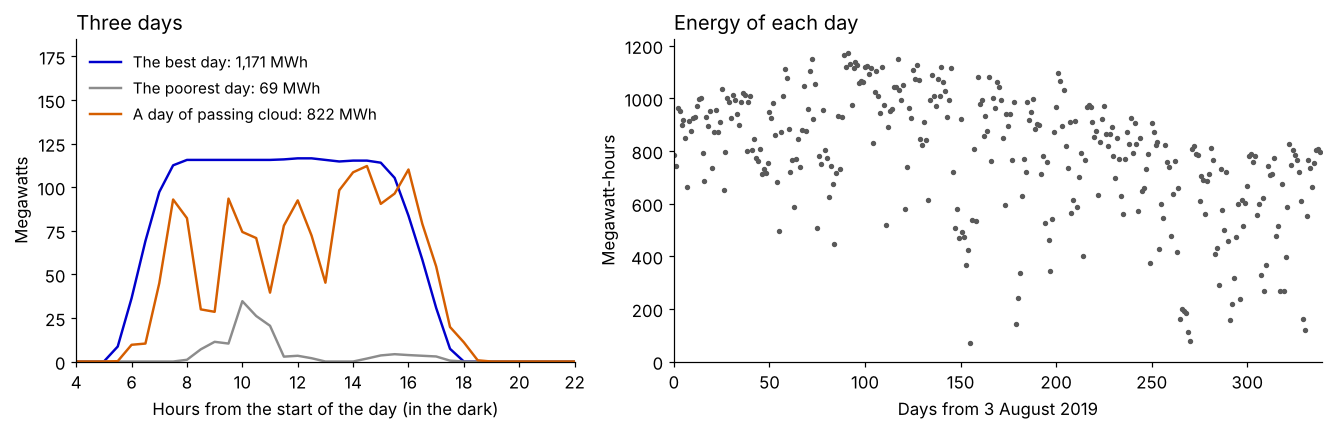

339 days of 48 half hours. Top output 116.5 megawatts.
Energy of a day: 69 to 1,171 megawatt-hours, 809 on the middle day.


In [2]:
output = load("solar-farm")["mw"]

DAY = 48        # half hours in a day
PAST = 28       # a forecast is built from this many past days

days = output.to_numpy().reshape(-1, DAY)                  # one row per day, megawatts by half hour
energy = days.sum(axis=1) / 2                              # megawatt-hours: half an hour at each level

rough = np.abs(np.diff(days, axis=1)).sum(axis=1)
middling = np.abs(energy - np.median(energy)) < 60
shown = {"The best day": int(energy.argmax()), "The poorest day": int(energy.argmin()),
         "A day of passing cloud": int(np.where(middling, rough, 0).argmax())}

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained", width_ratios=[1, 1.3])
for (label, day), color in zip(shown.items(), ("#0000CC", "0.55", "#D55E00")):
    left.plot(np.arange(DAY) / 2, days[day], color=color, linewidth=1.6,
              label=f"{label}: {energy[day]:,.0f} MWh")
left.set(title="Three days", xlabel="Hours from the start of the day (in the dark)",
         ylabel="Megawatts", xlim=(4, 22), ylim=(0, 185))
left.legend(loc="upper left", fontsize=10)
right.plot(np.arange(len(days)), energy, color="0.35", linewidth=0, marker="o", markersize=2.5)
right.set(title="Energy of each day", xlabel="Days from 3 August 2019", ylabel="Megawatt-hours",
          ylim=(0, None), xlim=(0, len(days)))
plt.show()

print(f"{len(days)} days of {DAY} half hours. Top output {days.max():.1f} megawatts.")
print(f"Energy of a day: {energy.min():,.0f} to {energy.max():,.0f} megawatt-hours, "
      f"{np.median(energy):,.0f} on the middle day.")
assert days.shape == (339, 48) and abs(days.max() - 116.5) < 0.01 and output.index.freqstr == "30min"

A clear day is a smooth arch, flat on top where the farm reaches its limit. Cloud takes bites out of it, sometimes for a few minutes and sometimes for the whole day, and the poorest day brought a seventeenth of the best.

## Two forecasts with the same half hours

A forecast in TimeGym can be a set of **samples**: each sample is one whole way the next 48 half hours could go. Two forecasters, both built from the last 28 days:

- **Whole days** hands over the last 28 days as they were. Each sample is one real day.
- **Shuffled half hours** hands over the same 28 values for every half hour, with each half hour's values in an order of its own. A sample takes 10:00 from one day and 10:30 from another.

For any single half hour the two say exactly the same thing: the same 28 values. This is what a forecast made half hour by half hour amounts to, when nothing ties the half hours together.

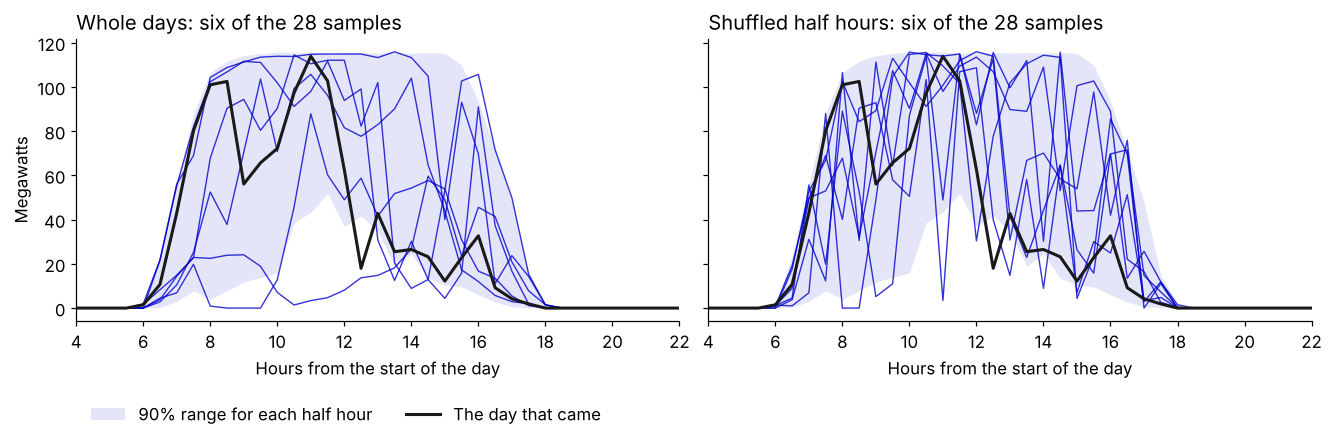

,Whole days,Shuffled half hours
Half-hour score (CRPS),6.912,6.912


311 forecast days. In daylight, the 90% range for a half hour held
82% of the time. It is the same range for both forecasters.


In [3]:
class WholeDays:
    "Each of the last 28 days, kept whole, is one way the next day could go."

    def fit(self, history):
        values = np.asarray(history, dtype=float).ravel()
        self.days_ = values[-PAST * DAY:].reshape(PAST, DAY)
        return self

    def predict(self, dates):
        return Forecast(dates, samples=self.days_[:, :, None])       # sample x half hour x series


class Shuffled(WholeDays):
    "The same 28 values for every half hour, each half hour in an order of its own."

    def predict(self, dates):
        rng = np.random.default_rng(0)
        mixed = np.column_stack([rng.permutation(values) for values in self.days_.T])
        return Forecast(dates, samples=mixed[:, :, None])


cases = cases_from_series(output, [day * DAY for day in range(PAST, len(days))], horizon=DAY, name="output")
runs = {"Whole days": Pipeline(WholeDays()).run(cases=cases),
        "Shuffled half hours": Pipeline(Shuffled()).run(cases=cases)}
for run in runs.values():
    counts = run.report.summary["status_counts"]
    assert counts["FAIL"] == counts["ERROR"] == 0, counts

came = days[PAST:]                                                    # what each forecast day brought
samples = {name: np.array([entry.forecast.samples[:, :, 0] for entry in run.cases])
           for name, run in runs.items()}                             # day x sample x half hour
scores = {name: pd.DataFrame([entry.result.metrics for entry in run.cases]) for name, run in runs.items()}

example = 180
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained", sharey=True)
for ax, (name, drawn) in zip(axes, samples.items()):
    low, high = np.quantile(drawn[example], [0.05, 0.95], axis=0)
    ax.fill_between(np.arange(DAY) / 2, low, high, color="#0000CC", alpha=0.10, linewidth=0,
                    label="90% range for each half hour")
    ax.plot(np.arange(DAY) / 2, drawn[example][:6].T, color="#0000CC", linewidth=0.9, alpha=0.8)
    ax.plot(np.arange(DAY) / 2, came[example], color="0.1", linewidth=2, label="The day that came")
    ax.set(title=f"{name}: six of the 28 samples", xlabel="Hours from the start of the day", xlim=(4, 22))
axes[0].set_ylabel("Megawatts")
axes[0].legend(ncols=2, loc="lower left", bbox_to_anchor=(0, -0.42))
plt.show()

half_hour = pd.DataFrame({name: {"Half-hour score (CRPS)": table["crps"].mean()} for name, table in scores.items()})
display(half_hour.round(3))
ends = {name: np.quantile(drawn, [0.05, 0.95], axis=1) for name, drawn in samples.items()}
daylight = ends["Whole days"][1] > 0.5
inside = (came >= ends["Whole days"][0]) & (came <= ends["Whole days"][1])
print(f"{len(cases)} forecast days. In daylight, the 90% range for a half hour held")
print(f"{inside[daylight].mean():.0%} of the time. It is the same range for both forecasters.")
assert np.allclose(ends["Whole days"], ends["Shuffled half hours"]) and len(cases) == 311
assert np.allclose(scores["Whole days"]["crps"], scores["Shuffled half hours"]["crps"])

The shaded range is the same in both panels, and so is the score for single half hours: the CRPS, which is the average miss of a forecast that comes as samples, counted one half hour at a time. No check made half hour by half hour can tell these two forecasts apart.

The lines are not the same. A whole day is a smooth arch or a ragged one. A shuffled sample jumps between good and bad days every half hour, which no day at this farm has ever done.

## Ask for the day's energy

Each sample adds up to a day's energy, so 28 samples give 28 totals and a range for the day. A third answer needs no samples, and is what people reach for when all they have is a range for each half hour: add up the low ends, and add up the high ends.

,Width (MWh),Held (%)
90% range for the day's energy,,
Adding up the half hours' ends,781.0,96.1
Shuffled half hours,185.0,33.4
Whole days,546.0,83.9


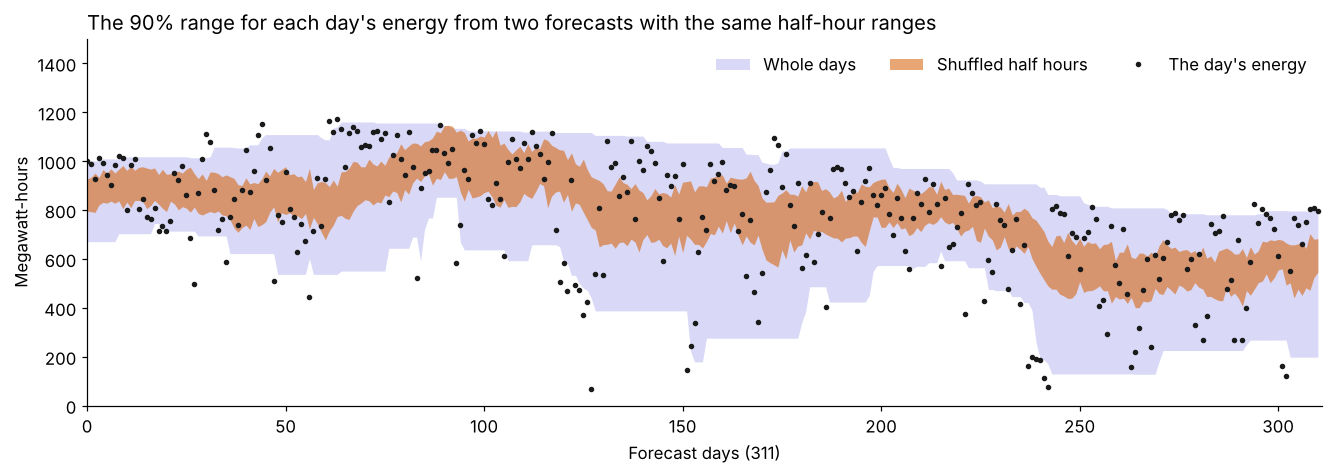

Shuffled half hours: the day came in below the range 29% of the time
and above it 38% of the time.


In [4]:
day_energy = energy[PAST:]


def day_range(drawn):
    "The 90% range for the day's energy that a set of samples implies."
    return np.quantile(drawn.sum(axis=2) / 2, [0.05, 0.95], axis=1)


ranges = {"Adding up the half hours' ends": ends["Whole days"].sum(axis=2) / 2,
          "Shuffled half hours": day_range(samples["Shuffled half hours"]),
          "Whole days": day_range(samples["Whole days"])}
held = {name: (day_energy >= low) & (day_energy <= high) for name, (low, high) in ranges.items()}
for_the_day = pd.DataFrame({name: {"Width (MWh)": (high - low).mean(), "Held (%)": 100 * held[name].mean()}
                            for name, (low, high) in ranges.items()}).T
display(for_the_day.round({"Width (MWh)": 0, "Held (%)": 1}).rename_axis("90% range for the day's energy"))

fig, ax = plt.subplots(figsize=(12, 4.2), layout="constrained")
day = np.arange(len(day_energy))
ax.fill_between(day, *ranges["Whole days"], color="#0000CC", alpha=0.15, linewidth=0, label="Whole days")
ax.fill_between(day, *ranges["Shuffled half hours"], color="#D55E00", alpha=0.55, linewidth=0,
                label="Shuffled half hours")
ax.plot(day, day_energy, color="0.1", linewidth=0, marker="o", markersize=2.6, label="The day's energy")
ax.set(title="The 90% range for each day's energy from two forecasts with the same half-hour ranges",
       xlabel=f"Forecast days ({len(day)})", ylabel="Megawatt-hours", xlim=(0, len(day)), ylim=(0, 1500))
ax.legend(ncols=3, loc="upper right")
plt.show()

below = {name: (day_energy < low).mean() for name, (low, high) in ranges.items()}
print(f"Shuffled half hours: the day came in below the range {below['Shuffled half hours']:.0%} of the time")
print(f"and above it {1 - below['Shuffled half hours'] - held['Shuffled half hours'].mean():.0%} of the time.")
assert np.allclose(for_the_day["Held (%)"], [96.1, 33.4, 83.9], atol=0.6), for_the_day
assert np.allclose(for_the_day["Width (MWh)"], [779, 185, 546], atol=8), for_the_day

The same half-hour ranges give three ranges for the day. Adding up the ends assumes every half hour is at its worst on the same day, and gives a range 43% wider than the one from whole days, which holds on 96% of days where 90% was asked for. Shuffling assumes a poor half hour says nothing about the next one. Good and bad then cancel out within every sample, the totals bunch together, and the range is a third of the width it should be: two days in three fall outside it. Keeping the days whole holds 84% of the time. That is short of 90%, and the last section looks at why.

## A score that sees it

We found the difference by asking about the day's energy. Had we asked about the longest dip, or the steepest climb, we would have had to check again. TimeGym scores every forecast that comes as samples three ways:

- **CRPS** looks at one half hour at a time.
- The **energy score** treats the whole day as one thing: how far the samples are from the day that came, against how far they are from each other. (The name comes from physics, not from megawatt-hours.)
- The **variogram score** compares the differences between pairs of half hours, in the samples and in the day that came. It is the one built to notice how the parts of a day move together.

In all three, lower is better.

In [5]:
names = {"crps": "CRPS", "energy_score": "Energy score", "variogram_score": "Variogram score"}
table = {}
for key, label in names.items():
    whole, shuffled = scores["Whole days"][key], scores["Shuffled half hours"][key]
    gap = paired_t_interval((shuffled - whole).to_numpy() / whole.mean() * 100)
    table[label] = {"Whole days": whole.mean(), "Shuffled": shuffled.mean(), "Shuffled worse by (%)": gap["mean"],
                    "from": gap["ci95"][0], "to": gap["ci95"][1]}
table = pd.DataFrame(table).T
decimals = {"Whole days": 2, "Shuffled": 2, "Shuffled worse by (%)": 1, "from": 1, "to": 1}
display(table.round(decimals) + 0.0)                       # adding 0.0 shows a rounded -0.0 as 0.0

assert abs(table["Shuffled worse by (%)"].iloc[0]) < 1e-9
assert (table["from"].iloc[1:] > 2).all() and table["Shuffled worse by (%)"].iloc[2] > 5

,Whole days,Shuffled,Shuffled worse by (%),from,to
CRPS,6.91,6.91,0.0,0.0,0.0
Energy score,85.74,89.30,4.1,3.2,5.1
Variogram score,3.33,3.56,6.7,5.6,7.8


The half-hour score cannot see the shuffling at all. The two scores for the whole day can: 4% and 7% worse on the same 311 days, with intervals clear of zero. Those are small numbers for a forecast whose range for the day is a third of the right width. A score for the whole day tells you which of two forecasts keeps the day together. It does not tell you how much that matters for your question; asking the question itself, as the last section did, shows the size.

## Where the answer is known

Two things are still open. Do the two scores favor whole days for some reason of their own? And is 84% in place of 90% a fault in the forecast? Both can be settled on generated series, where TimeGym knows the true range for the day's total.

Two kinds of series, 300 of each, the same length as the farm's history and with the same spread in every half hour:

- **No memory**: every half hour is drawn afresh. Shuffling destroys nothing here, because there is nothing to destroy.
- **Swings that last**: each half hour keeps nine tenths of the last one's departure from the average, so a low stretch lasts for hours.

In [6]:
length = dict(context_length=PAST * DAY, horizon=DAY)
kinds = {"No memory": Scenario("white_noise", **length, parameters={"mean": 50.0, "sigma": 10.0}),
         "Swings that last": Scenario("ar1", **length, parameters={"mean": 50.0, "phi": 0.9,
                                                                    "sigma": 10.0 * np.sqrt(1 - 0.9 ** 2)})}
rows = {}
for kind, scenario in kinds.items():
    row = {}
    for name, model in (("Whole days", WholeDays()), ("Shuffled", Shuffled())):
        run = Pipeline(model).run(scenarios=[scenario], instances=300)
        low, high = day_range(np.array([entry.forecast.samples[:, :, 0] for entry in run.cases]))
        total = np.array([np.asarray(entry.case.observed)[:, 0].sum() / 2 for entry in run.cases])
        row[f"{name}: width"] = (high - low).mean()
        row[f"{name}: held (%)"] = 100 * ((total >= low) & (total <= high)).mean()
        row[name] = np.array([entry.result.metrics["variogram_score"] for entry in run.cases])
    # The answer key: the true range for the total, from 2,000 draws of what could follow each history.
    truth = [np.quantile(entry.case.reference.sample(2000, seed=1)[:, :, 0].sum(axis=1) / 2, [0.05, 0.95])
             for entry in run.cases[:100]]
    row["True width"] = np.diff(truth, axis=1).mean()
    gap = paired_t_interval((row.pop("Shuffled") - row["Whole days"]) / row.pop("Whole days").mean() * 100)
    row["Variogram gap (%)"] = gap["mean"]
    rows[kind] = row
control = pd.DataFrame(rows)
order = ["True width", "Whole days: width", "Shuffled: width", "Whole days: held (%)", "Shuffled: held (%)",
         "Variogram gap (%)"]
display(control.loc[order].round(1).rename_axis("Range for the total of 48 half hours"))

assert abs(control["No memory"]["Variogram gap (%)"]) < 1 < 10 < control["Swings that last"]["Variogram gap (%)"]
assert abs(control["No memory"]["Shuffled: width"] / control["No memory"]["Whole days: width"] - 1) < 0.05
assert control["Swings that last"]["Shuffled: width"] < 0.3 * control["Swings that last"]["True width"]
assert 78 < control.loc["Whole days: held (%)"].min() and control.loc["Whole days: held (%)"].max() < 90

,No memory,Swings that last
Range for the total of 48 half hours,,
True width,108.5,425.8
Whole days: width,102.0,403.2
Shuffled: width,103.3,100.9
Whole days: held (%),81.7,86.3
Shuffled: held (%),84.0,29.3
Variogram gap (%),0.0,16.5


With no memory, shuffling changes nothing: the same width, the same share of totals held, no gap in the score. So the score has no taste for whole days as such. With swings that last, the shuffled range is a quarter of the true width and holds 29% of the time, and the score gap opens. That is close to what happened at the farm, where it was a third of the width and held 33%.

The same table answers the second question. Even where whole days are exactly the right forecast, a range read off 28 samples holds 82% to 86% of the time and not 90%, and it is a little narrower than the true one. The 5th and 95th of 28 numbers sit slightly inside the true ends. The farm's 84% is what 28 days can give.

## What TimeGym added

- **Forecasts made of samples.** A model hands back whole possible days in a `Forecast`, and the pipeline checks their shape and scores them like any other forecast.
- **Three scores for every sampled forecast.** The half-hour score could not tell the two forecasts apart. The two scores for the whole day could, and we did not have to know beforehand that the day's energy was the question.
- **Generated series with the true answer.** `Scenario` made series with and without lasting swings, and the answer key gave the true range for the total. That showed the score is fair to shuffling where shuffling is harmless, and that 84% is the price of 28 samples.
- **Every forecast kept.** The day's energy, its three ranges and the pictures were worked out from the kept samples after the runs.

## Change one thing

- Read the day's range off the lowest and the highest of the 28 totals. How often does it hold, and how wide is it?
- Set `PAST = 56`. Does the range for the day hold more often? What happens to the half-hour score?
- Shuffle in blocks: keep each run of four half hours together and shuffle the runs. How much of the gap closes?
- Ask another question of the kept samples: the chance of three hours in a row below 20 megawatts in daylight. Compare the two forecasts with what came.
- `load("solar-farm", full=True)` has the output every four seconds. Build the day from five-minute averages and see whether the gap grows.

**What this doesn't show.** This forecast knows nothing about tomorrow's weather. A real day-ahead forecast starts from a weather forecast, and TimeGym cannot yet hand a model an input that is known in advance. Such a forecast would be much sharper than the last four weeks, and it would face the same question: a range for each half hour, however good, says nothing about two half hours together. Shuffling is the extreme case. Forecasts made half hour by half hour often tie neighbors together in part, and land somewhere between the orange band and the blue one. This is one farm, which the archive does not name, over a little less than a year. Readings are missing from the archive's series in at least one place, so a day here is 48 half hours of the file and not always a calendar day. Days next to each other share their weather, so the 311 days are not independent and the intervals are somewhat too narrow.

**Related:** [River flow](river-flow.ipynb) checks a range month by month and [The S&P 500 next week](sp500.ipynb) year by year; both are about one step at a time. [Tomorrow's electricity demand](electricity-demand.ipynb) forecasts the other side of the same half-hourly market. [Univariate uncertainty](../tutorials/08_univariate_uncertainty.ipynb) covers forecasts made of samples, and [Multivariate uncertainty](../tutorials/09_multivariate_uncertainty.ipynb) scrambles one on generated series and reads the same three scores. More examples are on the [examples page](../docs/examples.md).